# Decision models с нуля: от hidden states к типизированному ответу

Этот notebook предполагает знакомство с GPT и BERT. Разбираем три readout-механизма
открытых аналогов Jev, затем маски, общий KV-prefix, обучение и калибровку.

**Учебный масштаб:** свой Transformer на PyTorch, синтетическая задача, без весов
Hugging Face и API. Здесь нет восстановления закрытой архитектуры Jev. Точные
отличия от Laya, Kev, SemIf и Nimble перечислены в [source guide](sources.md).

Запускайте ячейки сверху вниз. Основной код лежит в `model.py`, цикл обучения — в
`train.py`. Notebook показывает промежуточные величины, а не дублирует реализации.

В первой code cell выбирается `device`: на совместимом Mac — `mps` (Metal),
иначе — `cpu`. Для ручного выбора задайте `torch.device("mps")` или
`torch.device("cpu")` и выполните Restart Kernel → Run All. Модели и входные
тензоры должны находиться на одном устройстве.

После правок локальных `.py` запускайте **Run All с первой ячейки**: она
перезагружает модули и заново связывает импортированные функции. Повторное выполнение
одной нижней ячейки может использовать старую функцию из памяти ядра.

![Три readout-механизма](assets/architectures.png)

In [1]:
import importlib
import json
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch.nn import functional as F

roots = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for root in roots for p in (root, root / "tracks/decision-models")
            if (p / "upstreams.json").exists() and (p / "model.py").exists())
sys.path.insert(0, str(ROOT))

# Run All должен подхватывать изменения локальных .py даже в уже работающем ядре.
# Порядок важен: сначала зависимости, затем использующие их модули.
for module_name in ("data", "model", "calibration", "typed", "train", "inspect_model"):
    if module_name in sys.modules:
        importlib.reload(sys.modules[module_name])

from calibration import fit_temperature, metrics, proper_reward, rlcd_loss  # noqa: E402
from data import (  # noqa: E402
    CODES,
    WORDS,
    collate,
    decode,
    make_dataset,
    make_example,
    split_states,
)
from inspect_model import isolation_demo  # noqa: E402
from model import Config, DecisionModel, attention_mask, gather_positions  # noqa: E402
from typed import answer  # noqa: E402

# Metal в PyTorch называется mps. Для CPU задайте device = torch.device("cpu").
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
torch.set_num_threads(1)
torch.manual_seed(7)
plt.rcParams.update({"figure.facecolor": "#faf9f5", "axes.facecolor": "#faf9f5"})
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "| device:", device, "| folder:", ROOT.name)

Python: /Users/roman/dev/repos/MLIB/.venv-1/bin/python
PyTorch: 2.14.0 | device: mps | folder: decision-models


## 1. Классы входят в input

Состояние содержит цвета четырёх людей. Вопрос задаёт человека, варианты — список
цветов в случайном порядке. Таргет — **индекс** правильного описания в текущем списке.
Один и тот же цвет может быть A, B или C. Это минимальный аналог
$p(i\mid x,q,d_1,\ldots,d_K)$; семантику естественного языка модель здесь не изучает.

In [2]:
example = make_example(73, random.Random(3), n_options=3)
print(decode(example.tokens))
print("Вопрос:", example.person, "| варианты:", example.options)
print("Target index:", example.label, "| target text:", example.options[example.label])
for i, token in enumerate(example.tokens):
    mark = " ← start" if i in example.starts else " ← end" if i in example.ends else ""
    print(f"{i:2} {WORDS[token]:10}{mark}")

[STATE] bob violet carol blue alice amber dave red [SEP] [Q] bob [OPT] A violet [/OPT] [OPT] B green [/OPT] [OPT] C amber [/OPT] [DECIDE]
Вопрос: bob | варианты: ['violet', 'green', 'amber']
Target index: 0 | target text: violet
 0 [STATE]   
 1 bob       
 2 violet    
 3 carol     
 4 blue      
 5 alice     
 6 amber     
 7 dave      
 8 red       
 9 [SEP]     
10 [Q]       
11 bob       
12 [OPT]      ← start
13 A         
14 violet    
15 [/OPT]     ← end
16 [OPT]      ← start
17 B         
18 green     
19 [/OPT]     ← end
20 [OPT]      ← start
21 C         
22 amber     
23 [/OPT]     ← end
24 [DECIDE]  


## 2. Batch и формы тензоров

`B` — примеры, `L` — токены, `D` — hidden width, `K` — варианты, `H` — attention heads.
Padding по токенам и padding по вариантам — две разные маски. Padded option должен
получить вероятность 0. Padding не должен менять результат реального вопроса.

In [3]:
examples = [example, make_example(301, random.Random(9), n_options=5)]
batch = collate(examples, device=device)
for name, tensor in batch.items():
    print(f"{name:12} {str(tuple(tensor.shape)):10} {tensor.dtype}")
cfg = Config(width=32, heads=4, layers=2)
models = {kind: DecisionModel(kind, cfg).to(device).eval() for kind in ["token", "pointer", "marker"]}
print("Model device:", next(models["pointer"].parameters()).device, "| batch device:", batch["tokens"].device)
for kind, model in models.items():
    with torch.no_grad():
        logits = model(batch)
    print(kind, "logits:", tuple(logits.shape), "first p:", logits.softmax(-1)[0].tolist())
    assert torch.all(logits.softmax(-1)[0, 3:] == 0)
print("Эти модели пока со случайными весами: распределения не являются осмысленными решениями.")

tokens       (2, 33)    torch.int64
starts       (2, 5)     torch.int64
ends         (2, 5)     torch.int64
decision     (2,)       torch.int64
option_mask  (2, 5)     torch.bool
labels       (2,)       torch.int64
Model device: mps:0 | batch device: mps:0
token logits: (2, 5) first p: [0.20383480191230774, 0.1971324235200882, 0.5990328192710876, 0.0, 0.0]
pointer logits: (2, 5) first p: [0.3167884349822998, 0.29187774658203125, 0.3913337290287018, 0.0, 0.0]
marker logits: (2, 5) first p: [0.3262777030467987, 0.31845900416374207, 0.35526329278945923, 0.0, 0.0]
Эти модели пока со случайными весами: распределения не являются осмысленными решениями.


## 3. Под капотом attention

У всех учебных моделей один вид pre-norm блока: attention + residual, MLP + residual.
Меняется маска и readout. Здесь вручную повторим первую attention-операцию,
чтобы увидеть $[B,H,L,L]$ и проверить нормировку весов по ключам.

In [11]:
backbone = models["pointer"].backbone
ids = batch["tokens"]
positions = torch.arange(ids.size(1), device=ids.device)
x = backbone.token_embedding(ids) + backbone.position_embedding(positions)
layer = backbone.blocks[0]
B, L, D = x.shape
H = cfg.heads
print("Input:", x.shape, "| heads:", H, "| head dim:", D // H)
q, k, v = layer.attn.qkv(layer.ln1(x)).reshape(B, L, 3, H, D // H).permute(2, 0, 3, 1, 4)
allow = attention_mask(ids, causal=True)
weights = ((q @ k.transpose(-2, -1)) / (D // H) ** 0.5).masked_fill(~allow, -torch.inf).softmax(-1)
print("Q/K/V:", q.shape, "| attention:", weights.shape)
torch.testing.assert_close(weights.sum(-1), torch.ones_like(weights.sum(-1)))
print("Запрещённые пути имеют нулевой вес:", bool((weights.masked_select(~allow) == 0).all()))

Input: torch.Size([2, 33, 32]) | heads: 4 | head dim: 8
Q/K/V: torch.Size([2, 4, 33, 8]) | attention: torch.Size([2, 4, 33, 33])
Запрещённые пути имеют нулевой вес: True


## 4. Три readout, разобранные вручную

**Token:** $z_i=W_{v_i}h_{decide}$ — строки LM-head для кодов A/B/C.
**Pointer:** $z_i=(W_qh_{decide})^T(W_kh_{end_i})/\sqrt D$.
**Marker:** $z_i=MLP(h_{start_i})$ при bidirectional attention.

У causal encoder маркер **перед** описанием ещё не видел текст своего варианта.
Поэтому pointer использует закрывающий `[/OPT]`. Bidirectional marker видит описание
справа. Используемые в Laya `[MASK]` служат аналогичными якорями, не MLM-заданием.

In [15]:
with torch.no_grad():
    token_model = models["token"]
    h = token_model.backbone(ids)[0]
    decide = gather_positions(h, batch["decision"][:, None]).squeeze(1)
    print("Decision token:", decide.shape, "→ hidden state:", h.shape)
    full_vocab = token_model.readout.lm_head(decide)
    selected = full_vocab[:, CODES]
    torch.testing.assert_close(selected, token_model.readout(h, batch))
    print("Token: full vocab", full_vocab.shape, "→ selected", selected.shape)

    pointer = models["pointer"]
    h = pointer.backbone(ids)[0]
    query = pointer.readout.query(gather_positions(h, batch["decision"][:, None]))
    keys = pointer.readout.key(gather_positions(h, batch["ends"]))
    pointer_scores = (query * keys).sum(-1) / D ** 0.5
    torch.testing.assert_close(pointer_scores, pointer.readout(h, batch))
    print("Pointer:", query.shape, "×", keys.shape, "→", pointer_scores.shape)

    marker = models["marker"]
    h = marker.backbone(ids)[0]
    anchors = gather_positions(h, batch["starts"])
    marker_scores = marker.readout.scorer(anchors).squeeze(-1)
    torch.testing.assert_close(marker_scores, marker.readout(h, batch))
    print("Marker:", anchors.shape, "→", marker_scores.shape)

Decision token: torch.Size([2, 32]) → hidden state: torch.Size([2, 33, 32])
Token: full vocab torch.Size([2, 21]) → selected torch.Size([2, 5])
Pointer: torch.Size([2, 1, 32]) × torch.Size([2, 5, 32]) → torch.Size([2, 5])
Marker: torch.Size([2, 5, 32]) → torch.Size([2, 5])


## 5. Маска — это граф зависимостей

В prefill все входные токены уже известны; causal mask не требует последовательного
выполнения каждого токена. Генерация появляется только при подаче предсказанного
токена обратно в модель. В decision model такого цикла нет.

![Разрешённые пути информации](assets/attention_masks.png)

Для двух вопросов попробуем три способа: отдельные полные forward, общую packed
последовательность с branch mask и prefill состояния с переиспользованием K/V.

In [16]:
report, packed_tokens, segments, position_ids, branch_allow = isolation_demo(device=device)
print("Mask/cache device:", packed_tokens.device)
print(json.dumps(report, indent=2))
print("position IDs:", position_ids.tolist())
for name in ["packed_vs_separate_q1", "packed_vs_separate_q2", "cached_vs_full_q1", "cached_vs_full_q2"]:
    assert report[name] < 2e-5
assert report["prefix_unchanged"]
assert report["q1_change_after_editing_q2"] < 2e-5
assert report["q2_change_after_editing_q1"] < 2e-5

Mask/cache device: mps:0
{
  "packed_vs_separate_q1": 2.384185791015625e-07,
  "packed_vs_separate_q2": 4.76837158203125e-07,
  "cached_vs_full_q1": 4.76837158203125e-07,
  "cached_vs_full_q2": 4.76837158203125e-07,
  "q1_change_after_editing_q2": 0.0,
  "q2_change_after_editing_q1": 0.0,
  "q2_error_without_position_reset": 3.0735180377960205,
  "prefix_unchanged": true
}
position IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


Сброс position IDs делает каждую ветку продолжением **state**, независимо от её
физического положения в packed tensor. Без сброса маска изолирует информацию, но
позиционные embeddings уже другие. Ненулевой `q2_error_without_position_reset`
показывает эту ошибку.

Cache в этом примере не изменяется на месте. Suffix-ветки исполняются последовательно
ради простоты кода; их batching в production требует отдельной реализации. Здесь
проверяется численная эквивалентность, а не обещается ускорение.

## 6. Минимальный цикл обучения

Ниже — намеренное переобучение на 16 примерах. Оно проверяет путь градиента от
classification loss до embeddings и не измеряет обобщение. Для полноценного
эксперимента с тремя независимыми split используйте `train.py --model all`.

Loss: 1.0163 → 0.0
Accuracy на тех же 16 обучающих примерах: 1.0


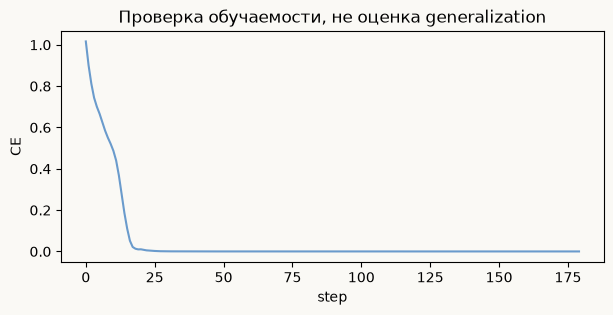

In [17]:
torch.manual_seed(7)
learning_model = DecisionModel("pointer", cfg).to(device)
tiny_batch = collate(make_dataset(split_states()["train"], 16, seed=19), device=device)
optimizer = torch.optim.AdamW(learning_model.parameters(), lr=0.003)
losses = []
for _ in range(180):
    logits = learning_model(tiny_batch)
    loss = F.cross_entropy(logits, tiny_batch["labels"])
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    losses.append(float(loss.detach()))
with torch.no_grad():
    seen_accuracy = learning_model(tiny_batch).argmax(-1).eq(tiny_batch["labels"]).float().mean()
print("Loss:", round(losses[0], 4), "→", round(losses[-1], 4))
print("Accuracy на тех же 16 обучающих примерах:", float(seen_accuracy))
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(losses, color="#6a9bcc")
ax.set(xlabel="step", ylabel="CE", title="Проверка обучаемости, не оценка generalization")
plt.show()

## 7. RLCD как открытый учебный эксперимент

TypeSafe не раскрывает свой RLCD. В нашем `rlcd_loss` действие — noisy logits,
reward оценивает всё распределение. Логарифм policy дифференцируется по исходным
логитам при **detached** sampled action. Иначе reparameterization может обнулить
нужный score-function gradient. Добавлен CE, как в открытом notebook Laya.

Здесь baseline leave-one-out; это оговорённое отличие от group-mean + normalization
в Laya. CE уже proper loss. Этот пример не доказывает превосходство RL над CE.

In [8]:
torch.manual_seed(11)
probe_logits = torch.tensor([[0.1, 0.2, 0.3]], device=device, requires_grad=True)
probe_mask = torch.ones_like(probe_logits, dtype=torch.bool)
policy_loss = rlcd_loss(probe_logits, torch.tensor([0], device=device), probe_mask,
                        group_size=256, ce_weight=0.0)
policy_loss.backward()
print("Policy gradient без CE:", probe_logits.grad.tolist())

target = torch.tensor([0., 1., 0.], device=device)
for values in [[0.1, 0.8, 0.1], [0.8, 0.1, 0.1]]:
    p = torch.tensor(values, device=device)
    print(p.tolist(), "reward:", float(proper_reward(p, target)),
          "ordinal reward:", float(proper_reward(p, target, ordinal=True)))

Policy gradient без CE: [[-0.9617856740951538, 0.4905487298965454, 0.4712368845939636]]
[0.10000000149011612, 0.800000011920929, 0.10000000149011612] reward: 0.2692224383354187 ordinal reward: 0.25922244787216187
[0.800000011920929, 0.10000000149011612, 0.10000000149011612] reward: -2.241039276123047 ordinal reward: -2.5660393238067627


## 8. Калибровка после обучения

Применим обученную выше модель к отдельным состояниям. Температуру выбираем только
на calibration split; NLL/Brier/ECE считаем на test. Хорошая калибровка не исправит
неспособность обобщать после переобучения на 16 примерах. Общая положительная
температура сохраняет argmax и accuracy, но меняет вероятности.

In [9]:
splits = split_states()
learning_model.eval()
with torch.no_grad():
    cal_batch = collate(make_dataset(splits["calibration"], 120, seed=100), device=device)
    test_batch = collate(make_dataset(splits["test"], 150, seed=200), device=device)
    cal_logits = learning_model(cal_batch)
    test_logits = learning_model(test_batch)
temperature = fit_temperature(cal_logits, cal_batch["labels"])
before = metrics(test_logits, test_batch["labels"])
after = metrics(test_logits, test_batch["labels"], temperature)
for key in ["accuracy", "nll", "brier", "ece", "temperature"]:
    print(f"{key:12}: {before[key]:.4f} → {after[key]:.4f}")
assert before["accuracy"] == after["accuracy"]

accuracy    : 0.2800 → 0.2800
nll         : 8.1699 → 1.4036
brier       : 1.3696 → 0.8082
ece         : 0.6886 → 0.2895
temperature : 1.0000 → 10.0000


## 9. Choice, Score и Noul — способы прочитать распределение

Ниже входные logits заданы вручную, чтобы проверить **арифметику интерфейса**.
Это не модельные предсказания. Score усредняет индексы уровней. Concentration на
основе энтропии не равна вероятности правильности и не воспроизводит формулу Jev.

In [10]:
print(answer(torch.tensor([0.2, 0.3, 0.5], device=device).log(), ["low", "medium", "high"], "choice"))
print(answer(torch.tensor([0.2, 0.3, 0.5], device=device).log(), ["low", "medium", "high"], "score"))
print(answer(torch.tensor([0.3, 0.7], device=device).log(), ["false", "true"], "noul"))

{'type': 'choice', 'choice': 'high', 'probabilities': {'low': 0.20000001788139343, 'medium': 0.30000004172325134, 'high': 0.5}, 'concentration': 0.06276938372365559}
{'type': 'score', 'score': 1.3000000715255737, 'probabilities': {'low': 0.20000001788139343, 'medium': 0.30000004172325134, 'high': 0.5}, 'concentration': 0.06276938372365559}
{'type': 'noul', 'noul': 0.699999988079071, 'probabilities': {'false': 0.30000001192092896, 'true': 0.699999988079071}}


## 10. Переход к настоящим исходникам

В [sources.md](sources.md) указаны файлы, функции и зафиксированные версии четырёх
upstream-проектов. Начните с SemIf `direct.py`, затем Kev `PointerHead`, Laya
`DecisionModel.forward`, Nimble `schema_train.py`. Вопросы для чтения:

1. Что нормализуется: весь vocabulary или только варианты?
2. Представление варианта успело увидеть его описание?
3. Где повторяется обработка state: tokenizer, backbone или cache?
4. Изоляция вопросов обеспечивается mask, отдельной batch row или обоими способами?
5. Какие данные использованы для обучения, выбора checkpoint и температуры?

Дальнейшие эксперименты описаны в [tutorial.md](tutorial.md). Реальные результаты
полного учебного прогона, если они присутствуют, лежат в `assets/training_experiment.json`.